# 03 — Mô hình và khoảng tin cậy

- **Mô hình điểm:** Gradient Boosting.
- **Đường cơ sở:** hồi quy tuyến tính theo số chu kỳ; hồi quy tuyến tính đủ đặc trưng.
- **Khoảng tin cậy 90%:** Conformalized Quantile Regression — học phân vị 5% và 95%, hiệu chỉnh bằng một cell riêng để đảm bảo độ phủ.
- **Kiểm định:** để riêng từng cell (leave-one-battery-out), tránh rò rỉ dữ liệu giữa các chu kỳ của cùng một pin.

In [1]:
import sys, json
sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import soh_pipeline as S
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e4e3df'})
COL = {'B0005': '#2a78d6', 'B0006': '#eb6834', 'B0007': '#1baf7a', 'B0018': '#6250d6'}
df = S.dataset()
p, m = S.evaluate(df)
pd.Series({'MAE Gradient Boosting': m['mae'], 'MAE tuyến tính đủ đặc trưng': m['mae_baseline_linear_all'], 'MAE tuyến tính theo chu kỳ': m['mae_baseline_cycles_only'], 'RMSE': m['rmse'], 'Độ phủ khoảng 90%': m['coverage_90'], 'Độ rộng TB (điểm %)': m['mean_width']}).round(3)

MAE Gradient Boosting           2.532
MAE tuyến tính đủ đặc trưng     2.516
MAE tuyến tính theo chu kỳ      4.217
RMSE                            3.321
Độ phủ khoảng 90%               0.885
Độ rộng TB (điểm %)            14.406
dtype: float64

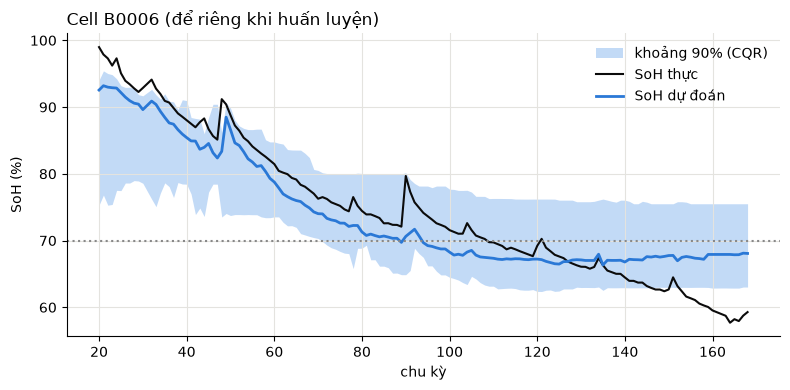

In [2]:
g = p[p.cell == 'B0006']
fig, ax = plt.subplots()
ax.fill_between(g.full_cycles, g.lo, g.hi, color='#86b6ef', alpha=.5, lw=0, label='khoảng 90% (CQR)')
ax.plot(g.full_cycles, g.soh, color='#0b0b0b', lw=1.5, label='SoH thực')
ax.plot(g.full_cycles, g.pred, color='#2a78d6', lw=2, label='SoH dự đoán')
ax.axhline(70, color='#888', ls=':')
ax.set_xlabel('chu kỳ'); ax.set_ylabel('SoH (%)'); ax.set_title('Cell B0006 (để riêng khi huấn luyện)', loc='left'); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig('../outputs/fig-pred-b0006.png', dpi=150); plt.show()